# Tittel på prosjektet

## Beskrivelse
xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx

- Melissa Visnjic
- Fredrik Brun

# 1. Laste inn pakker og datasett

510 kontrakter i CUADv1.json | 102 test | 408 train


,Antall klausultyper,Antall kontrakter
0,0,62
1,1,85
2,2,118
3,3,100
4,4,82
5,5,46
6,6,17


Antall kontrakter med alle 6 klausultypene: 17
Fjernet: 1779 tomme felter (kontrakt/kategori uten klausul), 0 tomme svar, 0 med feil posisjon, 0 dubletter
ann: 2239 annoterte passasjer | contracts: 510 kontrakter


,kategori,kontrakter med klausul,kontrakter uten,passasjer totalt,andel med klausul
0,Expiration Date,413,97,467,0.81
1,Renewal Term,176,334,210,0.35
2,Notice to Terminate Renewal,111,399,122,0.22
3,Cap on Liability,275,235,672,0.54
4,IP Ownership Assignment,124,386,318,0.24
5,Post-Termination Services,182,328,450,0.36


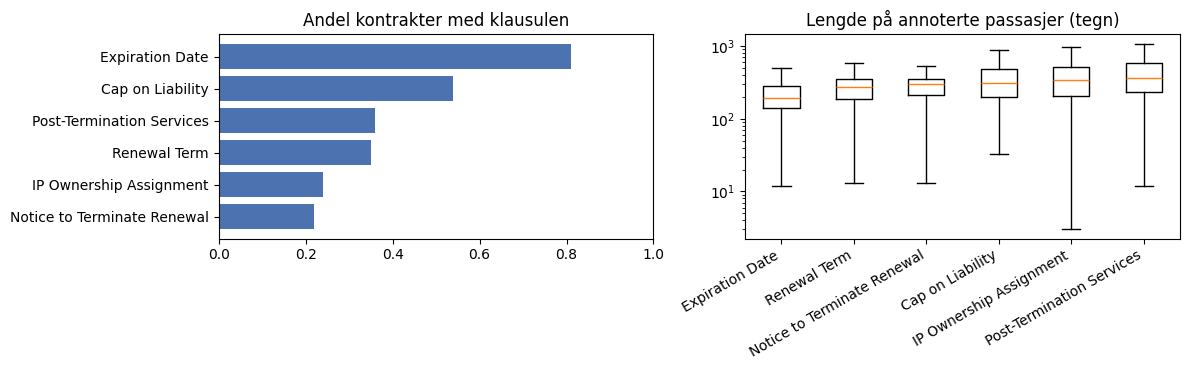

100 dev | 102 test | 308 reserve


,dev,test
Expiration Date,82,78
Renewal Term,42,26
Notice to Terminate Renewal,27,16
Cap on Liability,59,44
IP Ownership Assignment,25,23
Post-Termination Services,44,29


,metode,kategori,TP,FP,FN,TN,presisjon,recall,F1,span_recall,span_presisjon
0,søk,Expiration Date,68,9,14,9,0.883,0.829,0.855,0.349,0.283
1,søk,Renewal Term,37,23,5,35,0.617,0.881,0.725,0.396,0.364
2,søk,Notice to Terminate Renewal,23,27,4,46,0.460,0.852,0.597,0.441,0.347
3,søk,Cap on Liability,43,5,16,36,0.896,0.729,0.804,0.317,0.347
4,søk,IP Ownership Assignment,21,18,4,57,0.538,0.840,0.656,0.323,0.353
5,søk,Post-Termination Services,32,21,12,35,0.604,0.727,0.660,0.332,0.359


Makro-F1 (snitt over kategorier): 0.716
=== Baseline: falske negative ===
--- Expiration Date | DOMINIADVISORTRUST_02_18_2005-EX-99.(H)(2)-SPONSORSHIP AGREE
FASIT: ['This Agreement shall become effective as of the day and year first above written and shall govern the relations between the parties hereto thereafter, unless terminated as set forth in this Section 6.']
METODE: []
--- Expiration Date | GLOBALTECHNOLOGIESLTD_06_08_2020-EX-10.16-CONSULTING AGREEME
FASIT: ['This Agreement shall be in full force and effect commencing on January 2, 2020 and shall remain in effect for one (1) year or until Consultant completes the services requested']
METODE: []
--- Expiration Date | AzulSa_20170303_F-1A_EX-10.3_9943903_EX-10.3_Maintenance Agr
FASIT: ['This Amendment shall enter into force on the date of its signature by both Parties and, unless otherwise agreed upon in writing by the Parties through a subsequent amendment to the GMA, shall remain in force for the term of the referenced GMA.']
M

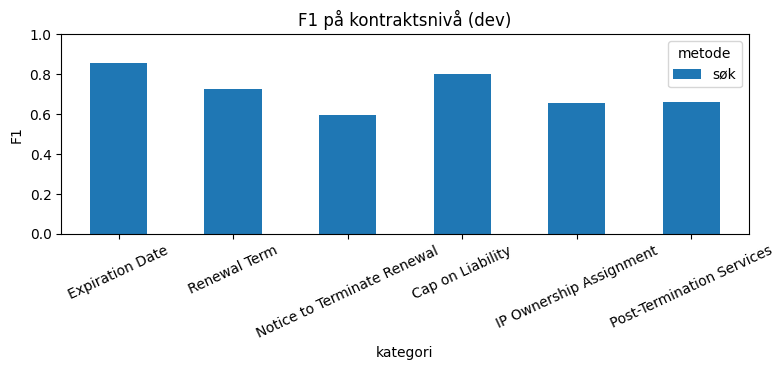

Lagret i C:\Users\melo1\OneDrive - NTNU\Desktop\LLM-Prosjekt\llmProject\data\processed


In [2]:
import json          # lese JSON-filene
import re            # regulære uttrykk: søk i tekst og rensing
import random        # tilfeldig trekning av dev-kontrakter (med fast seed)
import hashlib       # lager unik nøkkel til cache av LLM-kall
from pathlib import Path          # håndtere filstier
from collections import Counter   # telle ting (brukes i token-F1)
 
import pandas as pd              # tabeller
import numpy as np               # tall og logaritmiske akser
import matplotlib.pyplot as plt  # grafer

DATA_DIR = Path("data")                  # legg de tre JSON-filene her
OUT_DIR  = DATA_DIR / "processed"; OUT_DIR.mkdir(parents=True, exist_ok=True)


# dele opp i test, trening data
FULL_FILE  = DATA_DIR / "CUADv1.json"
TEST_FILE  = DATA_DIR / "test.json"
TRAIN_FILE = DATA_DIR / "train_separate_questions.json"


CATEGORIES = {
    "Expiration Date":                    "Expiration Date",
    "Renewal Term":                       "Renewal Term",
    "Notice Period To Terminate Renewal": "Notice to Terminate Renewal",
    "Cap On Liability":                   "Cap on Liability",
    "Ip Ownership Assignment":            "IP Ownership Assignment",
    "Post-Termination Services":          "Post-Termination Services",
}
CATS = list(CATEGORIES)
 
SEED = 42          # fast tilfeldighetsfrø, slik at oppdelingen blir lik hver gang
DEV_SIZE = 100     # antall kontrakter i dev-settet (trekkes fra train-delen)
 
# LLM-innstillinger. RUN_LLM = False betyr at alt unntatt LLM-kall kjøres (gratis).
RUN_LLM = False
MODEL = "gpt-4.1-mini"     # VALG: velg etter innledende utprøving (kvalitet/kostnad)
TEMPERATURE = 0            # 0 = mest mulig deterministisk svar
CHUNK_CHARS = 20000        # VALG: størrelse på tekstbiter for lange kontrakter
OVERLAP_CHARS = 2000       # VALG: overlapp mellom bitene, så en klausul ikke deles midt i
N_LLM_DEV = 10             # antall dev-kontrakter i første LLM-test (sjekk kostnad først!)
CACHE_DIR = Path("cache")  # alle LLM-svar lagres her (sparer penger og gir reproduserbarhet)
 
# %%
# ============================================================
# 2. IMPORTER DATAFILENE FRA MAPPEN data/
# ============================================================
# Vi leter etter filene på slutten av filnavnet, slik at det ikke spiller noen rolle om
# nedlastingen har satt et tallprefiks foran (f.eks. 1792400252854_CUADv1.json).
def finn_fil(slutt):
    treff = sorted(DATA_DIR.glob(f"*{slutt}"))
    if not treff:
        raise FileNotFoundError(f"Fant ingen fil som slutter på '{slutt}' i {DATA_DIR.resolve()}")
    return treff[0]
 
FULL_FILE = finn_fil("CUADv1.json")                      # alle 510 kontrakter, alle annotasjoner
TEST_FILE = finn_fil("test.json")                        # offisiell test-del (102 kontrakter)
TRAIN_FILE = finn_fil("train_separate_questions.json")   # train-del (408 kontrakter)
 
def les_json(path):
    # CUAD-filene følger SQuAD-formatet: {"version": ..., "data": [kontrakter]}
    with open(path, encoding="utf-8") as f:
        return json.load(f)["data"]
 
raw_full = les_json(FULL_FILE)
test_titles = [d["title"] for d in les_json(TEST_FILE)]
train_titles = [d["title"] for d in les_json(TRAIN_FILE)]
 
# Fasiten henter vi kun fra CUADv1.json (alle annoterte passasjer per kategori).
# test.json og train-filen brukes bare til å vite hvilke kontrakter som hører til test og train.
print(len(raw_full), "kontrakter i CUADv1.json |", len(test_titles), "test |", len(train_titles), "train")
assert set(test_titles).isdisjoint(train_titles), "Overlapp mellom train og test!"
assert set(test_titles) | set(train_titles) == {d["title"] for d in raw_full}
 
# %%
# ============================================================
# 3. RENS DATAENE
# ============================================================
# Hver kontrakt har 41 spørsmål (én per klausultype). Hvert spørsmål har en liste "answers" med
# de annoterte passasjene. Er listen tom, finnes ikke klausulen i kontrakten ("tomt felt").
#
# Rensingen gjøres i to steg:
#   a) Behold bare de seks kategoriene vi skal bruke (dropper de øvrige 35).
#   b) Fjern tomme felter: tomme svar, svar der posisjonen (answer_start) ikke stemmer med
#      teksten, og dubletter.
#
# Resultatet blir to strukturer:
#   ann       = tabell med én rad per annotert passasje. Her finnes IKKE tomme felter.
#               Bra til utforsking, few-shot-eksempler og lengdestatistikk.
#   contracts = én post per kontrakt med fasit per kategori. Her beholdes kontraktene UTEN
#               klausul (tom liste). De trengs i evalueringen, ellers kan vi ikke måle falske
#               positive, og dermed ikke presisjon.

# ============================================================
# TABELL: ANTALL KONTRAKTER MED 0–6 KLAUSULTYPER
# ============================================================

# Tell hvor mange av de seks klausultypene hver kontrakt inneholder
for d in contracts:
    d["antall_klausuler"] = sum(d["has"].values())

# Lag tabell med antall kontrakter for hvert antall klausultyper
tabell = (
    pd.Series([d["antall_klausuler"] for d in contracts])
    .value_counts()
    .reindex(range(7), fill_value=0)
    .sort_index()
    .rename_axis("Antall klausultyper")
    .reset_index(name="Antall kontrakter")
)

display(tabell)

# Antall kontrakter som inneholder samtlige seks klausultyper
alle_seks = sum(d["antall_klausuler"] == 6 for d in contracts)

print(f"Antall kontrakter med alle 6 klausultypene: {alle_seks}")

########################
 
def kategori_fra_id(qa_id):
    # id har formen "<kontrakttittel>__<kategori>"
    return qa_id.split("__")[-1]
 
def norm_ws(s):
    # Samler all whitespace til ett mellomrom. Brukes når tekster sammenlignes.
    return re.sub(r"\s+", " ", s.replace("\xa0", " ")).strip()
 
def clean_for_llm(text):
    # Forsiktig tekstrensing til språkmodellen: bare mellomrom og tomme linjer, ikke innhold.
    # Originalteksten røres ikke, fordi fasitens posisjoner peker i den.
    t = text.replace("\r\n", "\n").replace("\xa0", " ")
    t = re.sub(r"[ \t]+", " ", t)       # flere mellomrom eller tabs blir ett
    t = re.sub(r" ?\n ?", "\n", t)      # fjern mellomrom rundt linjeskift
    t = re.sub(r"\n{3,}", "\n\n", t)    # maks én tom linje
    return t.strip()
 
def in_text(passage, text):
    # Står utdraget ordrett i teksten (bortsett fra whitespace)? Avslører hallusinerte utdrag.
    return norm_ws(passage) in norm_ws(text)
 
rows = []                                  # rader til ann-tabellen
contracts = []                             # én post per kontrakt
n_uten_svar = n_tom = n_feil_pos = n_dubl = 0
 
for doc in raw_full:
    tekst = doc["paragraphs"][0]["context"]       # hele kontrakten ligger i ett avsnitt
    gold = {c: [] for c in CATS}
    for qa in doc["paragraphs"][0]["qas"]:
        kat = kategori_fra_id(qa["id"])
        if kat not in CATEGORIES:
            continue                              # steg a: hopp over de 35 andre kategoriene
        if not qa["answers"]:
            n_uten_svar += 1                      # tomt felt: ingen klausul i denne kontrakten
            continue
        for a in qa["answers"]:
            t, s = a["text"], a["answer_start"]
            if not t.strip():
                n_tom += 1                        # steg b: tomt svar
                continue
            if tekst[s:s + len(t)] != t:
                n_feil_pos += 1                   # steg b: posisjonen stemmer ikke med teksten
                continue
            gold[kat].append({"text": t, "start": s, "end": s + len(t)})
    for kat in CATS:
        unike = {(g["start"], g["end"]): g for g in gold[kat]}      # fjern dubletter
        n_dubl += len(gold[kat]) - len(unike)
        gold[kat] = sorted(unike.values(), key=lambda g: g["start"])
        for g in gold[kat]:
            rows.append({"title": doc["title"], "kategori": kat, **g})
    contracts.append({
        "title": doc["title"],
        "text": tekst,                            # original (brukes til posisjoner)
        "text_llm": clean_for_llm(tekst),         # renset utgave som sendes til modellen/søket
        "n_chars": len(tekst),
        "gold": gold,
        "has": {c: len(gold[c]) > 0 for c in CATS},   # fasit på kontraktsnivå: finnes klausulen?
    })
 
ann = pd.DataFrame(rows)
ann["n_chars"] = ann["text"].str.len()
print(f"Fjernet: {n_uten_svar} tomme felter (kontrakt/kategori uten klausul), {n_tom} tomme svar, "
      f"{n_feil_pos} med feil posisjon, {n_dubl} dubletter")
print(f"ann: {len(ann)} annoterte passasjer | contracts: {len(contracts)} kontrakter")
 
# %%
# ============================================================
# 4. OVERSIKT OG GRAFER
# ============================================================
oversikt = pd.DataFrame({
    "kategori": [CATEGORIES[c] for c in CATS],
    "kontrakter med klausul": [sum(d["has"][c] for d in contracts) for c in CATS],
    "kontrakter uten": [sum(not d["has"][c] for d in contracts) for c in CATS],
    "passasjer totalt": [int((ann["kategori"] == c).sum()) for c in CATS],
})
oversikt["andel med klausul"] = (oversikt["kontrakter med klausul"] / len(contracts)).round(2)
display(oversikt)
 
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
# Graf 1: andel kontrakter som har klausulen (viser klasseskjevhet)
o = oversikt.sort_values("andel med klausul")
ax[0].barh(o["kategori"], o["andel med klausul"], color="#4C72B0")
ax[0].set_xlim(0, 1); ax[0].set_title("Andel kontrakter med klausulen")
# Graf 2: lengde på annoterte passasjer (viktig for token-F1)
ax[1].boxplot([ann.loc[ann["kategori"] == c, "n_chars"] for c in CATS], showfliers=False)
ax[1].set_xticks(range(1, len(CATS) + 1)); ax[1].set_xticklabels([CATEGORIES[c] for c in CATS], rotation=30, ha="right")
ax[1].set_yscale("log"); ax[1].set_title("Lengde på annoterte passasjer (tegn)")
plt.tight_layout(); plt.show()
 
# %%
# ============================================================
# 5. DEL I DEV OG TEST (på kontraktsnivå)
# ============================================================
# Test = CUADs offisielle test-del. Den røres ikke før metodene er ferdig tilpasset.
# Dev  = tilfeldig utvalg fra train-delen. Her utvikler vi søkeregler og prompt.
# Reserve = resten av train (f.eks. til few-shot-eksempler).
# Delingen skjer per kontrakt, så tekst fra samme kontrakt aldri havner i både dev og test.
shuffled = sorted(train_titles)
random.Random(SEED).shuffle(shuffled)
dev_titles = set(shuffled[:DEV_SIZE])
 
for d in contracts:
    d["split"] = "test" if d["title"] in set(test_titles) else ("dev" if d["title"] in dev_titles else "reserve")
 
dev = [d for d in contracts if d["split"] == "dev"]
test = [d for d in contracts if d["split"] == "test"]
print(len(dev), "dev |", len(test), "test |", len(contracts) - len(dev) - len(test), "reserve")
 
antall = pd.DataFrame({
    "dev": [sum(d["has"][c] for d in dev) for c in CATS],
    "test": [sum(d["has"][c] for d in test) for c in CATS],
}, index=[CATEGORIES[c] for c in CATS])
display(antall)    # antall kontrakter MED klausul i hver delmengde
 
# %%
# ============================================================
# 6. BASELINE: SØKEBASERT METODE
# ============================================================
# Idé: del kontrakten i avsnitt, gi hvert avsnitt poeng etter hvor mange nøkkeluttrykk som
# treffer, og returner de beste avsnittene hvis poengsummen er høy nok.
# Finnes ingen treff, svarer metoden "ingen klausul".
# Uttrykkene under er bare et STARTPUNKT: tilpass dem på dev-data (aldri på test).
PATTERNS = {
    "Expiration Date": [r"expire[sd]?", r"expiration", r"shall terminate on", r"initial term", r"continue in (full )?force"],
    "Renewal Term": [r"renew", r"automatically extend", r"successive (one|two|\d+)[- ]year", r"additional term"],
    "Notice Period To Terminate Renewal": [r"non-?renew", r"notice of (non-?renewal|termination)", r"prior written notice", r"not (to )?renew"],
    "Cap On Liability": [r"in no event shall .{0,80}liab", r"aggregate liability", r"shall not exceed", r"limitation of liability"],
    "Ip Ownership Assignment": [r"hereby assigns?", r"work made for hire", r"all right, title,? and interest", r"exclusive property"],
    "Post-Termination Services": [r"upon (termination|expiration)", r"following (termination|expiration)", r"transition services", r"wind[- ]down"],
}
COMPILED = {c: [re.compile(p, re.I) for p in ps] for c, ps in PATTERNS.items()}
 
def split_passages(text, min_len=40):
    # Del opp i avsnitt (tom linje mellom). Svært lange avsnitt deles videre på linjeskift.
    out = []
    for p in (x.strip() for x in re.split(r"\n\s*\n", text)):
        out.extend(p.split("\n") if len(p) > 3000 else [p])
    return [p.strip() for p in out if len(p.strip()) >= min_len]
 
MIN_SCORE, TOP_K = 1, 2     # VALG: terskel og maks antall utdrag. Tune på dev.
 
def keyword_predict(contract, cat):
    scored = []
    for p in split_passages(contract["text_llm"]):
        score = sum(1 for rx in COMPILED[cat] if rx.search(p))   # antall nøkkeluttrykk som treffer
        if score >= MIN_SCORE:
            scored.append((score, p))
    scored.sort(key=lambda x: -x[0])
    return [p for _, p in scored[:TOP_K]]       # tom liste = "fant ingen klausul"
 
# %%
# ============================================================
# 7. LLM-METODE
# ============================================================
# Kontrakten deles i overlappende biter. Modellen får én bit og én klausultype om gangen og
# svarer med JSON: {"found": true/false, "passages": ["ordrett utdrag", ...]}.
# Utdragene fra alle bitene samles på kontraktsnivå. Alle kall caches på disk.
DESCRIPTIONS = {   # korte definisjoner av klausultypene i prompten (kan finpusses etter CUAD-guiden)
    "Expiration Date": "The date or condition on which the agreement expires or the initial term ends.",
    "Renewal Term": "How long the agreement is renewed or extended for after the initial term.",
    "Notice Period To Terminate Renewal": "How far in advance notice must be given to prevent renewal or terminate at the end of a term.",
    "Cap On Liability": "Any cap or limit on a party's liability (for example a maximum amount or a time limit for claims).",
    "Ip Ownership Assignment": "Provisions assigning or allocating ownership of intellectual property created under the agreement.",
    "Post-Termination Services": "Obligations or services that continue or must be provided after termination or expiration.",
}
 
SYSTEM_PROMPT = (
    "You are a careful contract-analysis assistant. You are given part of a commercial contract and a clause type. "
    "Decide whether this text contains a clause of that type. If so, return the relevant passages copied VERBATIM "
    "from the text (do not paraphrase; keep each passage as short as possible while covering the provision). "
    "If there is no such clause, say so. Respond ONLY with JSON: "
    '{"found": true/false, "passages": ["..."]}'
)
 
def make_chunks(text, size=CHUNK_CHARS, overlap=OVERLAP_CHARS):
    # Korte kontrakter sendes hele. Lange deles i biter på 'size' tegn med 'overlap' tegn overlapp.
    if len(text) <= size:
        return [text]
    chunks, i = [], 0
    while True:
        chunks.append(text[i:i + size])
        if i + size >= len(text):
            return chunks
        i += size - overlap
 
client = None
if RUN_LLM:
    from openai import OpenAI            # pip install openai
    client = OpenAI()                    # leser OPENAI_API_KEY fra miljøet (aldri hardkod nøkkelen)
    CACHE_DIR.mkdir(exist_ok=True)
 
def llm_call(chunk, cat):
    user = f"Clause type: {cat}\nDefinition: {DESCRIPTIONS[cat]}\n\nContract text:\n<<<\n{chunk}\n>>>"
    key = hashlib.sha256((MODEL + str(TEMPERATURE) + SYSTEM_PROMPT + user).encode()).hexdigest()
    f = CACHE_DIR / f"{key}.json"
    if f.exists():                       # samme kall er gjort før: bruk lagret svar
        return json.load(open(f, encoding="utf-8"))
    resp = client.chat.completions.create(
        model=MODEL, temperature=TEMPERATURE, response_format={"type": "json_object"},
        messages=[{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}],
    )
    out = {"model": MODEL, "raw": resp.choices[0].message.content,
           "usage": resp.usage.model_dump() if resp.usage else None}
    json.dump(out, open(f, "w", encoding="utf-8"))
    return out
 
def llm_predict(contract, cat):
    text = contract["text_llm"]
    funnet = []
    for ch in make_chunks(text):
        try:
            d = json.loads(llm_call(ch, cat)["raw"])
        except json.JSONDecodeError:
            continue                                      # ugyldig JSON: hopp over denne biten
        if d.get("found"):
            funnet += [p for p in d.get("passages", []) if isinstance(p, str) and p.strip()]
    # Fjern dubletter (pga. overlapp) og forkast utdrag som ikke står ordrett i kontrakten.
    seen, final = set(), []
    for p in funnet:
        if p not in seen and in_text(p, text):
            seen.add(p); final.append(p)
    return final
 
# %%
# ============================================================
# 8. EVALUERING
# ============================================================
# To nivåer:
#  (a) Kontraktsnivå: er det funnet en klausul i kontrakter som har en? Presisjon, recall, F1.
#      Positiv i fasit = kontrakten har minst én annotert passasje.
#      Positiv fra metoden = metoden returnerer minst ett utdrag.
#  (b) Passasjenivå: hvor godt treffer utdraget riktig tekst? Token-F1 (overlapp i ord).
#      Vi matcher begge veier: hver fasitpassasje mot beste utdrag (recall-side),
#      og hvert utdrag mot beste fasitpassasje (presisjons-side).
def tokens(s):
    return re.findall(r"\w+", s.lower())
 
def token_f1(a, b):
    ta, tb = tokens(a), tokens(b)
    if not ta or not tb:
        return 0.0
    felles = sum((Counter(ta) & Counter(tb)).values())
    if felles == 0:
        return 0.0
    p, r = felles / len(ta), felles / len(tb)
    return 2 * p * r / (p + r)
 
def span_scores(pred, gold):
    rec = sum(max(token_f1(p, g) for p in pred) for g in gold) / len(gold)
    prec = sum(max(token_f1(p, g) for g in gold) for p in pred) / len(pred)
    return rec, prec
 
def evaluate(predict_fn, data, cats, name):
    rows, details = [], []
    for cat in cats:
        tp = fp = fn = tn = 0
        recs, precs = [], []
        for k in data:
            gold = [g["text"] for g in k["gold"][cat]]
            pred = predict_fn(k, cat)
            details.append({"title": k["title"], "kategori": cat, "gold": gold, "pred": pred})
            if gold and pred:
                tp += 1
                r, p = span_scores(pred, gold); recs.append(r); precs.append(p)
            elif gold:
                fn += 1                       # klausul finnes, men metoden fant ingenting
            elif pred:
                fp += 1                       # ingen klausul, men metoden fant noe
            else:
                tn += 1
        P = tp / (tp + fp) if tp + fp else 0.0
        R = tp / (tp + fn) if tp + fn else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        rows.append({"metode": name, "kategori": CATEGORIES[cat], "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                     "presisjon": P, "recall": R, "F1": F,
                     "span_recall": np.mean(recs) if recs else np.nan,
                     "span_presisjon": np.mean(precs) if precs else np.nan})
    return pd.DataFrame(rows), details
 
# Baseline på dev (gratis)
res_kw, det_kw = evaluate(keyword_predict, dev, CATS, "søk")
display(res_kw.round(3))
print("Makro-F1 (snitt over kategorier):", round(res_kw["F1"].mean(), 3))
 
# LLM på en liten del av dev (koster penger: sett RUN_LLM = True og sjekk kostnaden først)
results = [res_kw]
det_llm = []
if RUN_LLM:
    res_llm, det_llm = evaluate(llm_predict, dev[:N_LLM_DEV], CATS, "LLM")
    display(res_llm.round(3))
    results.append(res_llm)
 
# %%
# ============================================================
# 9. FEILANALYSE
# ============================================================
# Se på konkrete feil: falske negative (FN) og falske positive (FP). Noter eksempler til rapporten
# (feil klausul, utdrag som bare delvis dekker bestemmelsen, tilsynelatende oppdiktede utdrag osv.).
def vis_feil(details, type_="FN", n=3, bredde=300):
    vist = 0
    for d in details:
        fn_ = d["gold"] and not d["pred"]
        fp_ = d["pred"] and not d["gold"]
        if (type_ == "FN" and fn_) or (type_ == "FP" and fp_):
            print(f"--- {CATEGORIES[d['kategori']]} | {d['title'][:60]}")
            print("FASIT:", [norm_ws(g)[:bredde] for g in d["gold"][:2]])
            print("METODE:", [norm_ws(p)[:bredde] for p in d["pred"][:2]])
            vist += 1
            if vist >= n:
                break
 
print("=== Baseline: falske negative ==="); vis_feil(det_kw, "FN")
print("=== Baseline: falske positive ==="); vis_feil(det_kw, "FP")
 
# Graf: F1 per kategori for metodene som er kjørt
alle = pd.concat(results)
piv = alle.pivot(index="kategori", columns="metode", values="F1").reindex([CATEGORIES[c] for c in CATS])
piv.plot.bar(figsize=(8, 3.8), rot=25, ylim=(0, 1), title="F1 på kontraktsnivå (dev)")
plt.ylabel("F1"); plt.tight_layout(); plt.show()
 
# %%
# ============================================================
# 10. LAGRE RESULTATER
# ============================================================
alle.to_csv(OUT_DIR / "resultater_dev.csv", index=False)
ann.to_csv(OUT_DIR / "annoterte_passasjer.csv", index=False)
 
# Dokumenter oppsettet (kreves for reproduserbarhet i oppgaven). API-nøkler skal aldri lagres.
config = {"model": MODEL, "temperature": TEMPERATURE, "chunk_chars": CHUNK_CHARS,
          "overlap_chars": OVERLAP_CHARS, "seed": SEED, "dev_size": DEV_SIZE,
          "min_score": MIN_SCORE, "top_k": TOP_K, "system_prompt": SYSTEM_PROMPT,
          "kategorier": CATS}
json.dump(config, open(OUT_DIR / "run_config.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print("Lagret i", OUT_DIR.resolve())

# 2. Rense data

# 3. xxx